# Laporan Praktikum 3 Pembelajaran Mesin (Kelas C)
**K-Means, K-Nearest Neighbors (KNN), dan Support Vector Machine (SVM)**

**Dataset**
- Judul: Amazon Sales Dataset (produk Amazon India)
- Sumber: Kaggle, https://www.kaggle.com/datasets/karkavelrajaj/amazon-sales-dataset (file `amazon.csv`)
- Ukuran: 1465 baris × 16 kolom (1351 produk unik setelah pembersihan)
- Makna data: data produk Amazon India yang memuat harga asli, harga diskon, persentase diskon, rating, jumlah rating, kategori, dan ulasan pembeli. Dipakai untuk memahami pola harga, diskon, dan popularitas produk (misalnya segmentasi produk atau memprediksi kategori dan tingkat diskon).

**Pemakaian pada tiap algoritma**
- K-Means: klasterisasi produk dari discounted_price, discount_percentage, rating, rating_count (tanpa target).
- KNN: target `main_category` (Electronics, Computers&Accessories, Home&Kitchen).
- SVM: target `kelas_diskon` (Diskon Tinggi / Diskon Rendah).

*Setiap langkah di bawah ditulis berurutan: kode, output, lalu penjelasan.*

# 4.1 K-Means Clustering

### Langkah 1. Import library

In [1]:
# Andani Zaki Ramadhan_202431037
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score

**Penjelasan:** Library yang diimpor: pandas dan numpy untuk data, matplotlib untuk grafik, StandardScaler untuk menyamakan skala, KMeans untuk klasterisasi, serta silhouette_score dan davies_bouldin_score untuk menilai kualitas klaster. Tidak ada output karena langkah ini hanya menyiapkan alat.

### Langkah 2. Baca dataset: head(), info(), describe()

In [2]:
# Andani Zaki Ramadhan_202431037
pd.set_option("display.max_colwidth", 25)   # potong teks panjang agar tabel mudah dibaca
df = pd.read_csv("amazon.csv")
print("Ukuran dataset (baris, kolom):", df.shape)
display(df.head())
df.info()
display(df.describe())

Ukuran dataset (baris, kolom): (1465, 16)
   product_id           product_name               category discounted_price actual_price discount_percentage rating rating_count          about_product                user_id              user_name              review_id           review_title         review_content               img_link           product_link
0  B07JW9H4J1  Wayona Nylon Braid...  Computers&Accessor...             ₹399       ₹1,099                 64%    4.2       24,269  High Compatibility...  AG3D6O4STAQKAY2UVG...  Manav,Adarsh gupta...  R3HXWT0LRP0NMF,R2A...  Satisfied,Charging...  Looks durable Char...  https://m.media-am...  https://www.amazon...
1  B098NS6PVG  Ambrane Unbreakabl...  Computers&Accessor...             ₹199         ₹349                 43%    4.0       43,994  Compatible with al...  AECPFYFQVRUWC3KGNL...  ArdKn,Nirbhay kuma...  RGIQEG07R9HS2,R1SM...  A Good Braided Cab...  I ordered this cab...  https://m.media-am...  https://www.amazon...
2  B096MSW6CT  S

**Penjelasan:** Dataset berisi 1465 baris dan 16 kolom. Semua kolom terbaca bertipe teks (str), termasuk harga, diskon, rating, dan jumlah rating, karena nilainya memuat simbol ₹, tanda koma, dan %. Karena itu describe() hanya menghasilkan count, unique, top, dan freq, bukan rata-rata atau simpangan baku. Kolom-kolom ini harus diubah menjadi angka pada langkah pembersihan.

### Langkah 3. Pembersihan data (dilakukan sekali, dipakai ketiga algoritma)

In [3]:
# Andani Zaki Ramadhan_202431037
print("isna().sum() SEBELUM pembersihan:")
print(df.isna().sum())

# 1) buang baris duplikat produk (product_id sama) supaya satu produk tidak muncul dua kali
df_clean = df.drop_duplicates(subset="product_id").copy()

# 2) ubah kolom harga/diskon/rating yang bertipe teks menjadi angka
for col in ["discounted_price", "actual_price"]:
    df_clean[col] = df_clean[col].str.replace("₹", "", regex=False).str.replace(",", "", regex=False).astype(float)
df_clean["discount_percentage"] = df_clean["discount_percentage"].str.replace("%", "", regex=False).astype(float)
df_clean["rating"] = pd.to_numeric(df_clean["rating"], errors="coerce")          # nilai "|" menjadi NaN
df_clean["rating_count"] = pd.to_numeric(df_clean["rating_count"].str.replace(",", "", regex=False), errors="coerce")

# 3) ambil kategori utama (level paling atas dari kolom category)
df_clean["main_category"] = df_clean["category"].str.split("|").str[0]

# 4) buang kolom yang tidak relevan (identitas, teks ulasan, link)
drop_cols = ["product_id", "product_name", "category", "about_product", "user_id", "user_name",
             "review_id", "review_title", "review_content", "img_link", "product_link"]
df_clean = df_clean.drop(columns=drop_cols)

print("\nisna().sum() SETELAH konversi tipe data (sebelum diisi):")
print(df_clean.isna().sum())

# 5) isi nilai kosong dengan median (tahan terhadap outlier)
for col in ["rating", "rating_count"]:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

print("\nisna().sum() SETELAH pembersihan:")
print(df_clean.isna().sum())
print("\nUkuran data bersih:", df_clean.shape)

isna().sum() SEBELUM pembersihan:
product_id             0
product_name           0
category               0
discounted_price       0
actual_price           0
discount_percentage    0
rating                 0
rating_count           2
about_product          0
user_id                0
user_name              0
review_id              0
review_title           0
review_content         0
img_link               0
product_link           0
dtype: int64

isna().sum() SETELAH konversi tipe data (sebelum diisi):
discounted_price       0
actual_price           0
discount_percentage    0
rating                 1
rating_count           2
main_category          0
dtype: int64

isna().sum() SETELAH pembersihan:
discounted_price       0
actual_price           0
discount_percentage    0
rating                 0
rating_count           0
main_category          0
dtype: int64

Ukuran data bersih: (1351, 6)


**Penjelasan:** Sebelum dibersihkan, isna() hanya menunjukkan 2 nilai kosong (rating_count). Setelah teks diubah menjadi angka, muncul 1 nilai kosong tambahan di rating, yaitu sel berisi karakter "|" yang sebelumnya tidak terlihat sebagai kosong. Langkah yang saya lakukan: (1) membuang baris dengan product_id kembar sehingga 1465 baris menjadi 1351 produk unik, (2) membuang simbol ₹, koma, dan % lalu mengubahnya ke float, (3) mengambil kategori level teratas sebagai main_category, (4) membuang kolom identitas, teks ulasan, dan link karena tidak relevan sebagai fitur numerik, (5) mengisi nilai kosong dengan median karena median tidak terpengaruh outlier. Setelah itu isna().sum() semuanya 0 dan data bersih berukuran 1351 × 6.

### Langkah 4. Pemilihan fitur dan korelasi

In [4]:
# Andani Zaki Ramadhan
num_cols = ["discounted_price", "actual_price", "discount_percentage", "rating", "rating_count"]
print("Korelasi antar fitur numerik:")
display(df_clean[num_cols].corr().round(3))

fitur_km = ["discounted_price", "discount_percentage", "rating", "rating_count"]
X_km = df_clean[fitur_km].copy()
print("Fitur klasterisasi:", fitur_km)

Korelasi antar fitur numerik:
                     discounted_price  actual_price  discount_percentage  rating  rating_count
discounted_price                1.000         0.962               -0.237   0.126        -0.024
actual_price                    0.962         1.000               -0.112   0.127        -0.034
discount_percentage            -0.237        -0.112                1.000  -0.162         0.003
rating                          0.126         0.127               -0.162   1.000         0.097
rating_count                   -0.024        -0.034                0.003   0.097         1.000
Fitur klasterisasi: ['discounted_price', 'discount_percentage', 'rating', 'rating_count']


**Penjelasan:** Korelasi discounted_price dengan actual_price sangat tinggi, yaitu 0,962, artinya keduanya hampir membawa informasi yang sama (harga). Jika keduanya dipakai, K-Means menghitung dimensi harga dua kali dalam jarak Euclidean sehingga harga mendominasi pembentukan klaster. Karena itu actual_price tidak saya pakai. Fitur yang dipilih: discounted_price (tingkat harga), discount_percentage (strategi diskon), rating (kualitas menurut pembeli), dan rating_count (popularitas). Korelasi antar keempatnya rendah (nilai mutlak paling besar 0,237), sehingga masing-masing membawa informasi berbeda.

### Langkah 5. Scatter plot sebaran data

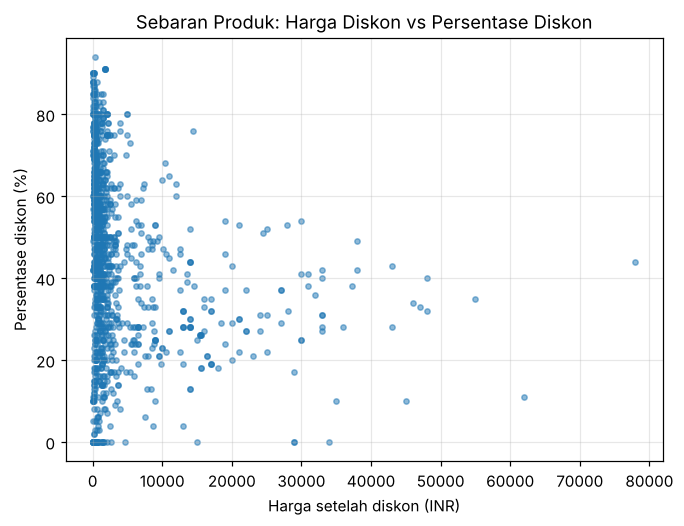

In [5]:
# Andani Zaki Ramadhan_202431037
plt.figure(figsize=(7, 5))
plt.scatter(X_km["discounted_price"], X_km["discount_percentage"], s=12, alpha=0.5)
plt.title("Sebaran Produk: Harga Diskon vs Persentase Diskon")
plt.xlabel("Harga setelah diskon (INR)")
plt.ylabel("Persentase diskon (%)")
plt.grid(alpha=0.3)
plt.show()

**Penjelasan:** Sebagian besar produk menumpuk di harga rendah dengan persentase diskon yang tersebar luas dari 0% sampai 94%, sedangkan sedikit produk mahal tersebar jauh ke kanan. Sebaran sangat miring dan tidak ada celah kosong yang tegas, jadi pemisahan klaster nantinya tidak akan sangat tajam.

### Langkah 6. Standarisasi fitur

In [6]:
# Andani Zaki Ramadhan_202431037
scaler_km = StandardScaler()
X_km_scaled = scaler_km.fit_transform(X_km)
print("Rata-rata tiap fitur setelah standarisasi:")
print(pd.Series(X_km_scaled.mean(axis=0), index=fitur_km).round(6))
print("\nSimpangan baku tiap fitur setelah standarisasi:")
print(pd.Series(X_km_scaled.std(axis=0), index=fitur_km).round(6))

Rata-rata tiap fitur setelah standarisasi:
discounted_price       0.0
discount_percentage    0.0
rating                -0.0
rating_count           0.0
dtype: float64

Simpangan baku tiap fitur setelah standarisasi:
discounted_price       1.0
discount_percentage    1.0
rating                 1.0
rating_count           1.0
dtype: float64


**Penjelasan:** Setelah StandardScaler, rata-rata keempat fitur 0 dan simpangan bakunya 1. Ini penting karena rating_count mencapai ratusan ribu sedangkan rating hanya 2 sampai 5; tanpa standarisasi, K-Means yang berbasis jarak hampir hanya akan melihat rating_count dan harga.

### Langkah 7. Inertia untuk k = 1 sampai 10

In [7]:
# Andani Zaki Ramadhan_202431037
inertia = []
k_range = range(1, 11)
for k in k_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=0)
    km.fit(X_km_scaled)
    inertia.append(km.inertia_)
    print(f"k = {k:2d}  inertia = {km.inertia_:.2f}")

k =  1  inertia = 5404.00
k =  2  inertia = 4244.04
k =  3  inertia = 3332.12
k =  4  inertia = 2535.30
k =  5  inertia = 1960.86
k =  6  inertia = 1745.21
k =  7  inertia = 1552.33
k =  8  inertia = 1357.30
k =  9  inertia = 1186.90
k = 10  inertia = 1094.43


**Penjelasan:** Inertia (jumlah kuadrat jarak titik ke centroid-nya) selalu turun ketika k naik, dari 5404,00 pada k=1 menjadi 1094,43 pada k=10. Nilainya sendiri tidak bisa dipakai memilih k karena pasti terus turun; yang dicari adalah titik ketika penurunannya mulai melambat.

### Langkah 8. Kurva elbow

Penurunan inertia dari k ke k+1:
  k=1 -> k=2: turun 1159.96
  k=2 -> k=3: turun 911.92
  k=3 -> k=4: turun 796.81
  k=4 -> k=5: turun 574.45
  k=5 -> k=6: turun 215.64
  k=6 -> k=7: turun 192.88
  k=7 -> k=8: turun 195.03
  k=8 -> k=9: turun 170.40
  k=9 -> k=10: turun 92.47


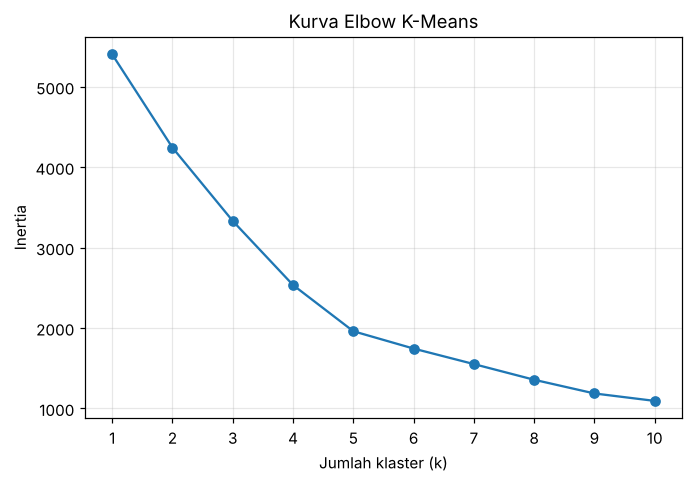

In [8]:
# NAMA_NIM
plt.figure(figsize=(7, 4.5))
plt.plot(list(k_range), inertia, marker="o")
plt.title("Kurva Elbow K-Means")
plt.xlabel("Jumlah klaster (k)")
plt.ylabel("Inertia")
plt.xticks(list(k_range))
plt.grid(alpha=0.3)
plt.show()

# penurunan inertia tiap kenaikan k, untuk membantu membaca siku kurva
turun = -np.diff(inertia)
print("Penurunan inertia dari k ke k+1:")
for k, t in zip(range(1, 10), turun):
    print(f"  k={k} -> k={k+1}: turun {t:.2f}")

**Penjelasan:** Penurunan inertia masih besar sampai k=5 (turun 574,45 dari k=4 ke k=5), lalu tiba-tiba mengecil menjadi 215,64 dari k=5 ke k=6 dan tetap landai sesudahnya. Siku kurva ada di k=5, sehingga k=5 menjadi kandidat utama (k=4 dan k=6 sebagai pembanding pada langkah berikutnya).

### Langkah 9. Silhouette score dan DBI untuk k = 2 sampai 6

In [9]:
# Andani Zaki Ramadhan_202431037
hasil = []
for k in range(2, 7):
    km = KMeans(n_clusters=k, n_init=10, random_state=0)
    label = km.fit_predict(X_km_scaled)
    hasil.append({"k": k,
                  "Silhouette (makin tinggi makin baik)": round(silhouette_score(X_km_scaled, label), 4),
                  "DBI (makin rendah makin baik)": round(davies_bouldin_score(X_km_scaled, label), 4)})
tabel_eval = pd.DataFrame(hasil)
display(tabel_eval)

   k  Silhouette (makin tinggi makin baik)  DBI (makin rendah makin baik)
0  2                 0.2837                                1.5211        
1  3                 0.3011                                1.1740        
2  4                 0.2995                                1.0011        
3  5                 0.3178                                0.9089        
4  6                 0.3271                                0.8634        


**Penjelasan:** Silhouette makin tinggi makin baik (rentang -1 sampai 1), sedangkan DBI makin rendah makin baik (mulai dari 0). Silhouette: 0,284 (k=2), 0,301 (k=3), 0,300 (k=4), 0,318 (k=5), 0,327 (k=6). DBI: 1,521; 1,174; 1,001; 0,909; 0,863. Kedua metrik terus membaik sampai k=6, tetapi selisih k=5 ke k=6 kecil (silhouette hanya naik 0,009). Saya memilih k=5 karena cocok dengan siku kurva elbow dan profil klasternya masih mudah dijelaskan.

### Langkah 10. Model akhir: centroid dan jumlah anggota

In [10]:
# Andani Zaki Ramadhan_202431037
K_FINAL = 5
km_final = KMeans(n_clusters=K_FINAL, n_init=10, random_state=0)
labels_km = km_final.fit_predict(X_km_scaled)

print("cluster_centers_ (ruang terstandarisasi):")
display(pd.DataFrame(km_final.cluster_centers_, columns=fitur_km).round(3))
print("Jumlah anggota tiap klaster:")
print(pd.Series(labels_km).value_counts().sort_index())

cluster_centers_ (ruang terstandarisasi):
   discounted_price  discount_percentage  rating  rating_count
0            -0.291                0.700   0.376        -0.104
1             3.866               -0.693   0.442        -0.140
2             0.040               -1.082   0.355        -0.114
3            -0.254               -0.013   0.209         4.793
4            -0.272                0.350  -1.457        -0.267
Jumlah anggota tiap klaster:
0    567
1     60
2    414
3     39
4    271
Name: count, dtype: int64


**Penjelasan:** Model akhir memakai k=5. Centroid dinyatakan dalam z-score: klaster 1 punya discounted_price +3,87 (jauh di atas rata-rata) dan klaster 3 punya rating_count +4,79 (jauh di atas rata-rata). Jumlah anggota: klaster 0 = 567, klaster 1 = 60, klaster 2 = 414, klaster 3 = 39, klaster 4 = 271 (total 1351). Dua klaster kecil (1 dan 3) berisi kelompok ekstrem yang memang jarang.

### Langkah 11. Visualisasi klaster dan centroid

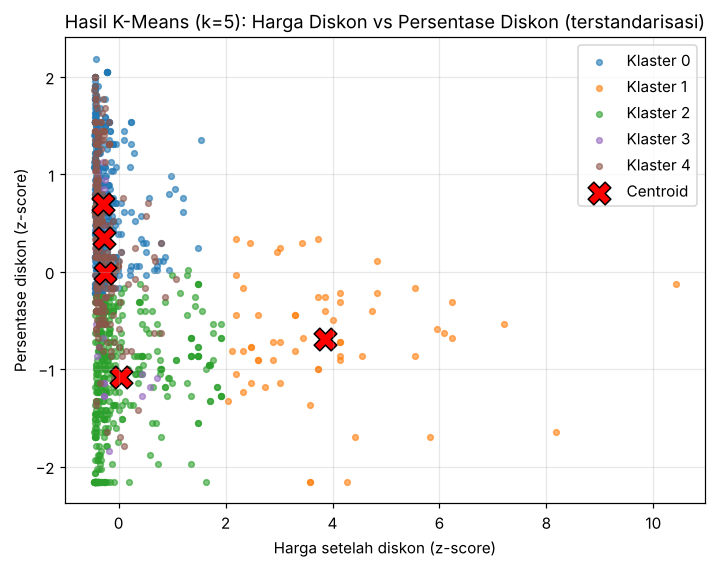

In [11]:
# NAMA_NIM
warna = ["tab:blue", "tab:orange", "tab:green", "tab:purple", "tab:brown", "tab:pink"]
plt.figure(figsize=(7.5, 5.5))
for c in range(K_FINAL):
    m = labels_km == c
    plt.scatter(X_km_scaled[m, 0], X_km_scaled[m, 1], s=14, alpha=0.6, color=warna[c], label=f"Klaster {c}")
plt.scatter(km_final.cluster_centers_[:, 0], km_final.cluster_centers_[:, 1],
            c="red", marker="X", s=220, edgecolor="black", label="Centroid")
plt.title(f"Hasil K-Means (k={K_FINAL}): Harga Diskon vs Persentase Diskon (terstandarisasi)")
plt.xlabel("Harga setelah diskon (z-score)")
plt.ylabel("Persentase diskon (z-score)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Penjelasan:** Titik berwarna menunjukkan anggota tiap klaster dan tanda X merah adalah centroid. Grafik hanya menampilkan dua dari empat fitur (harga dan persentase diskon), jadi beberapa klaster tampak bertumpuk karena pembedanya ada di fitur lain (rating dan rating_count).

### Langkah 12. Profil klaster

In [12]:
# Andani Zaki Ramadhan_202431037
df_profil = df_clean.copy()
df_profil["klaster"] = labels_km
profil = df_profil.groupby("klaster")[fitur_km].mean().round(2)
profil["jumlah"] = df_profil["klaster"].value_counts().sort_index()
display(profil)
nama_klaster = {
    0: "Murah, diskon besar",
    1: "Premium (harga tinggi)",
    2: "Menengah, diskon kecil",
    3: "Terlaris (ulasan sangat banyak)",
    4: "Murah, rating rendah",
}
df_profil["nama_klaster"] = df_profil["klaster"].map(nama_klaster)
print(pd.Series(nama_klaster, name="Nama klaster").to_string())

         discounted_price  discount_percentage  rating  rating_count  jumlah
klaster                                                                     
0                 1219.11                61.79    4.20      13213.14     567
1                31032.27                31.70    4.22      11743.28      60
2                 3591.88                23.23    4.20      12871.48     414
3                 1480.08                46.41    4.15     219400.59      39
4                 1353.72                54.26    3.66       6383.91     271
0         Murah, diskon besar
1      Premium (harga tinggi)
2      Menengah, diskon kecil
3    Terlaris (ulasan sang...
4        Murah, rating rendah


**Penjelasan:** Rata-rata fitur asli per klaster: klaster 0 harga ±1.219 dengan diskon 61,8%; klaster 1 harga ±31.032 dengan diskon 31,7%; klaster 2 harga ±3.592 dengan diskon 23,2%; klaster 3 punya rata-rata 219.401 rating; klaster 4 punya rating rata-rata hanya 3,66. Nama klaster berdasarkan profil: 0 = Murah, diskon besar; 1 = Premium (harga tinggi); 2 = Menengah, diskon kecil; 3 = Terlaris (ulasan sangat banyak); 4 = Murah, rating rendah.

### Langkah 13. Evaluasi akhir

In [13]:
# Andani Zaki Ramadhan_202431037
sil_final = silhouette_score(X_km_scaled, labels_km)
dbi_final = davies_bouldin_score(X_km_scaled, labels_km)
print(f"Silhouette score model akhir (k={K_FINAL}): {sil_final:.4f}")
print(f"Davies-Bouldin Index model akhir (k={K_FINAL}): {dbi_final:.4f}")

Silhouette score model akhir (k=5): 0.3178
Davies-Bouldin Index model akhir (k=5): 0.9089


**Penjelasan:** Silhouette score model akhir 0,3178 dan DBI 0,9089. Silhouette di sekitar 0,3 berarti struktur klaster ada tetapi lemah sampai sedang: banyak produk berada dekat batas antar klaster. Hal ini wajar karena data harga dan diskon produk bersifat kontinu dan tidak punya kelompok yang terpisah tegas. DBI di bawah 1 menunjukkan klaster rata-rata cukup padat dan berjarak satu sama lain. Dalam konteks data Amazon ini, hasilnya cukup untuk membagi produk menjadi segmen yang bisa ditafsirkan (premium, terlaris, murah berdiskon besar, dst.), tetapi bukan pemisahan yang sempurna.

# 4.2 K-Nearest Neighbors (KNN)

### Langkah 1. Import library

In [14]:
# Andani Zaki Ramadhan_202431037
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

**Penjelasan:** Library tambahan untuk klasifikasi: train_test_split dan GridSearchCV untuk membagi data serta mencari parameter, Pipeline dan StandardScaler agar penskalaan ikut dalam alur model, KNeighborsClassifier sebagai model, serta metrik evaluasi.

### Langkah 2. Baca dataset: head(), info(), describe()

In [15]:
# Andani Zaki Ramadhan_202431037
# dataset sama dengan bagian K-Means; df_clean sudah melalui pembersihan di awal (langkah 4.1)
df_knn_raw = pd.read_csv("amazon.csv")
print("Dataset mentah:", df_knn_raw.shape)
display(df_clean.head())
df_clean.info()
display(df_clean.describe())

Dataset mentah: (1465, 16)
   discounted_price  actual_price  discount_percentage  rating  rating_count          main_category
0             399.0        1099.0                 64.0     4.2       24269.0  Computers&Accessories
1             199.0         349.0                 43.0     4.0       43994.0  Computers&Accessories
2             199.0        1899.0                 90.0     3.9        7928.0  Computers&Accessories
3             329.0         699.0                 53.0     4.2       94363.0  Computers&Accessories
4             154.0         399.0                 61.0     4.2       16905.0  Computers&Accessories
<class 'pandas.DataFrame'>
Index: 1351 entries, 0 to 1464
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   discounted_price     1351 non-null   float64
 1   actual_price         1351 non-null   float64
 2   discount_percentage  1351 non-null   float64
 3   rating               1351 no

**Penjelasan:** Data yang dipakai adalah hasil pembersihan di langkah 4.1 (1351 baris, 6 kolom), jadi tidak perlu dibersihkan ulang. Lima kolom numerik bertipe float64 dan main_category bertipe teks yang akan menjadi target.

### Langkah 3. Periksa target dan kelasnya

In [16]:
# Andani Zaki Ramadhan_202431037
print(df_clean["main_category"].value_counts())
print("\nProporsi (%):")
print((df_clean["main_category"].value_counts(normalize=True) * 100).round(2))

# Arti kelas (target = kategori utama produk):
#   Electronics           -> perangkat elektronik (smartphone, TV, earphone, dll.)
#   Computers&Accessories -> komputer dan aksesorinya (kabel, mouse, dll.)
#   Home&Kitchen          -> peralatan rumah tangga dan dapur
#   Kategori lain hanya 1-31 baris, terlalu sedikit untuk dipelajari model

main_category
Electronics              490
Home&Kitchen             448
Computers&Accessories    375
OfficeProducts            31
MusicalInstruments         2
HomeImprovement            2
Toys&Games                 1
Car&Motorbike              1
Health&PersonalCare        1
Name: count, dtype: int64

Proporsi (%):
main_category
Electronics              36.27
Home&Kitchen             33.16
Computers&Accessories    27.76
OfficeProducts            2.29
MusicalInstruments        0.15
HomeImprovement           0.15
Toys&Games                0.07
Car&Motorbike             0.07
Health&PersonalCare       0.07
Name: proportion, dtype: float64


**Penjelasan:** Kelas terbesar adalah Electronics (490 produk, 36,3%), lalu Home&Kitchen (448, 33,2%) dan Computers&Accessories (375, 27,8%). Kelas lain hanya 1 sampai 31 produk sehingga terlalu sedikit untuk dipelajari model. Tiga kelas utama cukup seimbang (perbandingan terbesar : terkecil hanya sekitar 1,3 : 1), jadi akurasi masih bermakna sebagai ukuran, meski tetap dilengkapi precision dan recall.

### Langkah 4. Bersihkan dan siapkan data

In [17]:
# Andani Zaki Ramadhan_202431037
# Nilai kosong sudah ditangani di awal (median). Cek ulang:
print("Nilai kosong:", int(df_clean.isna().sum().sum()))

# Buang kelas yang terlalu sedikit anggotanya, sisakan 3 kelas utama
kelas_utama = ["Electronics", "Computers&Accessories", "Home&Kitchen"]
df_cls = df_clean[df_clean["main_category"].isin(kelas_utama)].copy()
print("Ukuran data klasifikasi:", df_cls.shape)
print(df_cls["main_category"].value_counts())
# Semua fitur sudah numerik, jadi tidak ada fitur kategori yang perlu di-encode

Nilai kosong: 0
Ukuran data klasifikasi: (1313, 6)
main_category
Electronics              490
Home&Kitchen             448
Computers&Accessories    375
Name: count, dtype: int64


**Penjelasan:** Tidak ada nilai kosong tersisa. Saya menyisakan tiga kelas utama sehingga data klasifikasi menjadi 1313 baris. Semua fitur sudah numerik, jadi tidak ada fitur kategori yang perlu diubah menjadi angka.

### Langkah 5. Pisahkan x dan y, lalu bagi data latih/uji

In [18]:
# Andani Zaki Ramadhan_202431037
fitur = ["discounted_price", "actual_price", "discount_percentage", "rating", "rating_count"]
X = df_cls[fitur]
y = df_cls["main_category"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0, stratify=y)
print("Jumlah data latih:", len(X_train))
print("Jumlah data uji  :", len(X_test))
print("\nProporsi kelas data latih:")
print(y_train.value_counts(normalize=True).round(3))
print("Proporsi kelas data uji:")
print(y_test.value_counts(normalize=True).round(3))

Jumlah data latih: 984
Jumlah data uji  : 329

Proporsi kelas data latih:
main_category
Electronics              0.373
Home&Kitchen             0.341
Computers&Accessories    0.286
Name: proportion, dtype: float64
Proporsi kelas data uji:
main_category
Electronics              0.374
Home&Kitchen             0.340
Computers&Accessories    0.286
Name: proportion, dtype: float64


**Penjelasan:** Fitur (x): discounted_price, actual_price, discount_percentage, rating, rating_count. Target (y): main_category. Data latih 984 baris dan data uji 329 baris. Karena memakai stratify=y, proporsi kelas pada data latih dan uji hampir sama (sekitar 0,37 / 0,34 / 0,29), jadi evaluasi tidak bias oleh pembagian data.

### Langkah 6. Periksa rentang fitur pada data latih

In [19]:
# Andani Zaki Ramadhan_202431037
rentang = pd.DataFrame({"min": X_train.min(), "max": X_train.max()})
rentang["lebar_rentang"] = rentang["max"] - rentang["min"]
display(rentang)
print("Fitur dengan rentang paling lebar:", rentang["lebar_rentang"].idxmax())

                      min       max  lebar_rentang
discounted_price     39.0   77990.0        77951.0
actual_price         39.0  139900.0       139861.0
discount_percentage   0.0      94.0           94.0
rating                2.0       5.0            3.0
rating_count          2.0  426973.0       426971.0
Fitur dengan rentang paling lebar: rating_count


**Penjelasan:** rating_count punya rentang paling lebar (2 sampai 426.971), disusul actual_price (39 sampai 139.900) dan discounted_price, sedangkan rating hanya 2 sampai 5. KNN memakai jarak, jadi fitur dengan rentang lebar akan mendominasi jarak dan fitur seperti rating hampir tidak berpengaruh bila tidak diskalakan.

### Langkah 7. Pipeline StandardScaler + KNN

In [20]:
# Andani Zaki Ramadhan_202431037
pipe_knn = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier())
])
print(pipe_knn)

Pipeline(steps=[('scaler', StandardScaler()), ('knn', KNeighborsClassifier())])


**Penjelasan:** Pipeline berisi StandardScaler lalu KNN. Dengan pipeline, scaler hanya belajar rata-rata dan simpangan baku dari data latih (dan hanya dari bagian latih pada setiap lipatan validasi silang), sehingga tidak ada kebocoran informasi dari data uji.

### Langkah 8. Pilih k dengan GridSearchCV (k = 1 sampai 19)

In [21]:
# Andani Zaki Ramadhan_202431037
param_knn = {"knn__n_neighbors": list(range(1, 20))}
grid_knn = GridSearchCV(pipe_knn, param_knn, cv=5, scoring="accuracy")
grid_knn.fit(X_train, y_train)      # hanya data latih

best_k = grid_knn.best_params_["knn__n_neighbors"]
print("k terbaik            :", best_k)
print("Skor validasi silang :", round(grid_knn.best_score_, 4))

k terbaik            : 10
Skor validasi silang : 0.6159


**Penjelasan:** GridSearchCV mencoba k = 1 sampai 19 dengan validasi silang 5 lipatan hanya pada data latih. k terbaik = 10 dengan akurasi validasi silang 0,6159. Data uji tidak disentuh pada langkah ini.

### Langkah 9. Latih model akhir dan prediksi data uji

In [22]:
# Andani Zaki Ramadhan_202431037
knn_final = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=best_k))
])
knn_final.fit(X_train, y_train)
y_pred_knn = knn_final.predict(X_test)
print("Contoh 10 prediksi pertama :", list(y_pred_knn[:10]))
print("Contoh 10 label asli       :", list(y_test.values[:10]))

Contoh 10 prediksi pertama : ['Electronics', 'Home&Kitchen', 'Home&Kitchen', 'Electronics', 'Home&Kitchen', 'Home&Kitchen', 'Home&Kitchen', 'Electronics', 'Computers&Accessories', 'Home&Kitchen']
Contoh 10 label asli       : ['Computers&Accessories', 'Electronics', 'Electronics', 'Electronics', 'Computers&Accessories', 'Home&Kitchen', 'Electronics', 'Home&Kitchen', 'Electronics', 'Home&Kitchen']


**Penjelasan:** Model akhir dilatih ulang pada seluruh data latih dengan k=10, lalu memprediksi data uji. Sepuluh contoh pertama menunjukkan sebagian prediksi benar dan sebagian salah, sebagai gambaran awal bahwa tugasnya tidak mudah.

### Langkah 10. Evaluasi: accuracy, classification report, confusion matrix

In [23]:
# Andani Zaki Ramadhan_202431037
print("Accuracy:", round(accuracy_score(y_test, y_pred_knn), 4))
print("\nClassification report:")
print(classification_report(y_test, y_pred_knn))
labels_urut = sorted(y.unique())
cm_knn = confusion_matrix(y_test, y_pred_knn, labels=labels_urut)
print("Confusion matrix (baris = asli, kolom = prediksi):")
display(pd.DataFrame(cm_knn, index=labels_urut, columns=labels_urut))

Accuracy: 0.5988

Classification report:
                       precision    recall  f1-score   support

Computers&Accessories       0.54      0.65      0.59        94
          Electronics       0.67      0.50      0.57       123
         Home&Kitchen       0.60      0.66      0.63       112

             accuracy                           0.60       329
            macro avg       0.60      0.60      0.60       329
         weighted avg       0.61      0.60      0.60       329

Confusion matrix (baris = asli, kolom = prediksi):
                       Computers&Accessories  Electronics  Home&Kitchen
Computers&Accessories                     61           14            19
Electronics                               31           62            30
Home&Kitchen                              21           17            74


**Penjelasan:** Akurasi data uji 0,5988 (sekitar 60%), jauh di atas tebakan acak (±33–37% untuk tiga kelas) tetapi belum tinggi: harga, diskon, dan rating tidak cukup untuk membedakan kategori produk dengan tegas. Untuk kelas Electronics: precision 0,67 artinya dari semua produk yang diprediksi Electronics, 67% memang Electronics; recall 0,50 artinya dari semua produk Electronics yang sebenarnya, hanya 50% yang berhasil ditemukan (31 dikira Computers&Accessories dan 30 dikira Home&Kitchen).

### Langkah 11. Uji satu data baru

In [24]:
# Andani Zaki Ramadhan_202431037
# titik baru: nilai tengah (median) data latih sehingga pasti berada di dalam rentang
titik_baru = pd.DataFrame([X_train.median()])
print("Titik data baru:")
display(titik_baru)
valid = ((titik_baru.iloc[0] >= X_train.min()) & (titik_baru.iloc[0] <= X_train.max())).all()
print("Semua fitur dalam rentang data latih:", valid)
print("Prediksi kelas:", knn_final.predict(titik_baru)[0])

Titik data baru:
   discounted_price  actual_price  discount_percentage  rating  rating_count
0             899.5        1825.0                 49.0     4.1        5065.5
Semua fitur dalam rentang data latih: True
Prediksi kelas: Home&Kitchen


**Penjelasan:** Titik baru dibuat dari nilai median tiap fitur pada data latih, sehingga semua fitur pasti berada di dalam rentang minimum–maksimum data latih (dicek di kode: True). Ini valid karena KNN hanya bisa dipercaya pada daerah yang punya tetangga nyata di data latih; titik di luar rentang berarti ekstrapolasi. Prediksinya Home&Kitchen.

### Langkah 12. Visualisasi skor validasi silang terhadap k

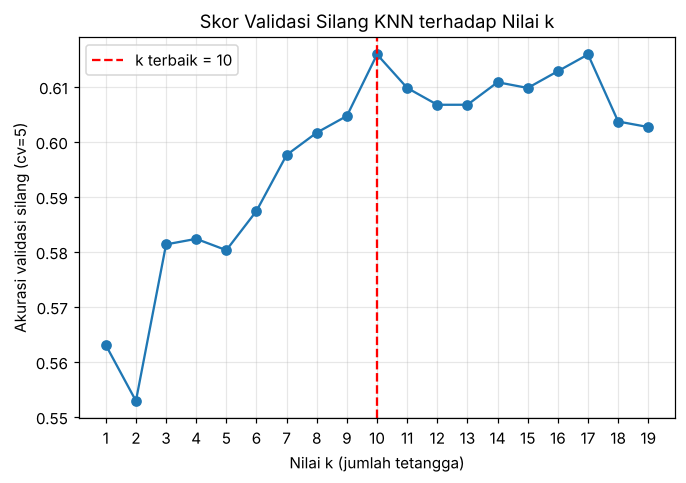

In [25]:
# Andani Zaki Ramadhan_202431037
mean_cv = grid_knn.cv_results_["mean_test_score"]
plt.figure(figsize=(7, 4.5))
plt.plot(range(1, 20), mean_cv, marker="o")
plt.axvline(best_k, color="red", linestyle="--", label=f"k terbaik = {best_k}")
plt.title("Skor Validasi Silang KNN terhadap Nilai k")
plt.xlabel("Nilai k (jumlah tetangga)")
plt.ylabel("Akurasi validasi silang (cv=5)")
plt.xticks(range(1, 20))
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Penjelasan:** Skor validasi silang rendah pada k kecil (0,563 pada k=1, tanda model terlalu mengikuti noise), naik sampai sekitar 0,616 di k=10, lalu relatif datar di kisaran 0,60–0,616 untuk k = 10 sampai 19 (k=17 hampir sama, 0,616). Grafik ini mendukung pemilihan k=10 tetapi menunjukkan hasil tidak sensitif terhadap k di rentang tersebut; pemilihan k tetap berdasarkan GridSearchCV.

# 4.3 Support Vector Machine (SVM)

### Langkah 1. Import library

In [26]:
# Andani Zaki Ramadhan_202431037
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

**Penjelasan:** Library untuk SVM: sama dengan KNN ditambah LabelEncoder untuk mengubah label teks menjadi angka dan SVC sebagai model.

### Langkah 2. Baca dataset: head(), info(), describe()

In [27]:
# Andani Zaki Ramadhan_202431037
display(df_cls.head())
df_cls.info()
display(df_cls.describe())

   discounted_price  actual_price  discount_percentage  rating  rating_count          main_category
0             399.0        1099.0                 64.0     4.2       24269.0  Computers&Accessories
1             199.0         349.0                 43.0     4.0       43994.0  Computers&Accessories
2             199.0        1899.0                 90.0     3.9        7928.0  Computers&Accessories
3             329.0         699.0                 53.0     4.2       94363.0  Computers&Accessories
4             154.0         399.0                 61.0     4.2       16905.0  Computers&Accessories
<class 'pandas.DataFrame'>
Index: 1313 entries, 0 to 1464
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   discounted_price     1313 non-null   float64
 1   actual_price         1313 non-null   float64
 2   discount_percentage  1313 non-null   float64
 3   rating               1313 non-null   float64
 4   ratin

**Penjelasan:** Lima kolom (discounted_price, actual_price, discount_percentage, rating, rating_count) bertipe float64, sedangkan main_category bertipe object (teks). Tidak ada kolom ID atau teks bebas yang tersisa; kolom itu sudah dibuang pada pembersihan awal.

### Langkah 3. Bersihkan data

In [28]:
# Andani Zaki Ramadhan_202431037
# Pembersihan sudah dilakukan di awal (langkah 4.1) dan dipakai bersama.
print("isna().sum():")
print(df_cls.isna().sum())

# Pada langkah 4.1 kolom product_id, product_name, user_id, user_name, review_*, about_product,
# img_link, dan product_link sudah dibuang karena hanya identitas/teks bebas dan tidak bisa dipakai
# SVC sebagai fitur numerik.
print("\nKolom yang tersisa:", list(df_cls.columns))

isna().sum():
discounted_price       0
actual_price           0
discount_percentage    0
rating                 0
rating_count           0
main_category          0
dtype: int64

Kolom yang tersisa: ['discounted_price', 'actual_price', 'discount_percentage', 'rating', 'rating_count', 'main_category']


**Penjelasan:** Tidak ada nilai kosong (semua 0), jadi tidak ada penanganan tambahan. Kolom product_id, nama produk, ulasan, user, dan link dibuang pada langkah 4.1 karena hanya identitas atau teks bebas yang tidak dapat dipakai SVC sebagai fitur numerik.

### Langkah 4. Periksa target

In [29]:
# Andani Zaki Ramadhan_202431037
# Target SVM: tingkat diskon produk (dibuat dari discount_percentage)
df_svm = df_cls.copy()
df_svm["kelas_diskon"] = np.where(df_svm["discount_percentage"] >= 50, "Diskon Tinggi", "Diskon Rendah")
print("Nilai unik target:", df_svm["kelas_diskon"].unique())
print(df_svm["kelas_diskon"].value_counts())

# Arti kelas:
#   Diskon Tinggi -> potongan harga >= 50%
#   Diskon Rendah -> potongan harga < 50%

Nilai unik target: <StringArray>
['Diskon Tinggi', 'Diskon Rendah']
Length: 2, dtype: str
kelas_diskon
Diskon Rendah    657
Diskon Tinggi    656
Name: count, dtype: int64


**Penjelasan:** Target untuk SVM dibuat berbeda dari KNN: kelas_diskon, yaitu Diskon Tinggi (diskon ≥ 50%) dan Diskon Rendah (< 50%). Jumlahnya hampir sama persis (657 vs 656). Karena target dibuat dari discount_percentage, kolom discount_percentage dan discounted_price tidak boleh dipakai sebagai fitur (akan membocorkan jawaban, sebab diskon dihitung dari kedua harga tersebut).

### Langkah 5. LabelEncoder untuk target dan fitur kategori

In [30]:
# Andani Zaki Ramadhan_202431037
le = LabelEncoder()
df_svm["target"] = le.fit_transform(df_svm["kelas_diskon"])
print("le.classes_ :", le.classes_)
for i, nama in enumerate(le.classes_):
    print(f"  {nama} -> {i}")

# fitur kategori main_category diubah menjadi angka
le_kat = LabelEncoder()
df_svm["main_category_enc"] = le_kat.fit_transform(df_svm["main_category"])
print("\nPemetaan main_category:", dict(zip(le_kat.classes_, le_kat.transform(le_kat.classes_))))

le.classes_ : ['Diskon Rendah' 'Diskon Tinggi']
  Diskon Rendah -> 0
  Diskon Tinggi -> 1

Pemetaan main_category: {'Computers&Accessories': np.int64(0), 'Electronics': np.int64(1), 'Home&Kitchen': np.int64(2)}


**Penjelasan:** LabelEncoder memetakan Diskon Rendah = 0 dan Diskon Tinggi = 1 (urutan alfabet). Fitur kategori main_category juga diubah menjadi angka: Computers&Accessories = 0, Electronics = 1, Home&Kitchen = 2. Perlu dicatat angka ini hanya kode, bukan urutan makna.

### Langkah 6. Pisahkan fitur dan target, bagi data (test_size=0.3)

In [31]:
# Andani Zaki Ramadhan_202431037
fitur_svm = ["actual_price", "rating", "rating_count", "main_category_enc"]
X_s = df_svm[fitur_svm]
y_s = df_svm["target"]

Xs_train, Xs_test, ys_train, ys_test = train_test_split(X_s, y_s, test_size=0.3, random_state=0)
print("Jumlah data latih:", len(Xs_train), "| Jumlah data uji:", len(Xs_test))
print("\nProporsi kelas data latih:")
print(ys_train.value_counts(normalize=True).round(3))
print("Proporsi kelas data uji:")
print(ys_test.value_counts(normalize=True).round(3))

Jumlah data latih: 919 | Jumlah data uji: 394

Proporsi kelas data latih:
target
1    0.504
0    0.496
Name: proportion, dtype: float64
Proporsi kelas data uji:
target
0    0.51
1    0.49
Name: proportion, dtype: float64


**Penjelasan:** Fitur SVM: actual_price, rating, rating_count, dan main_category_enc. Data latih 919 baris, data uji 394 baris. Proporsi kelas latih 0,504 / 0,496 dan uji 0,51 / 0,49, sudah hampir sama, sehingga stratify tidak mutlak diperlukan pada kasus ini.

### Langkah 7. Pipeline StandardScaler + SVC

In [32]:
# Andani Zaki Ramadhan_202431037
pipe_svm = Pipeline([
    ("scaler", StandardScaler()),
    ("svc", SVC())
])
print(pipe_svm)

Pipeline(steps=[('scaler', StandardScaler()), ('svc', SVC())])


**Penjelasan:** Scaler diletakkan di dalam pipeline agar statistiknya hanya dipelajari dari data latih. Ini penting untuk SVM karena kernel RBF dan margin sangat sensitif terhadap skala fitur.

### Langkah 8. Grid parameter

In [33]:
# Andani Zaki Ramadhan_202431037
param_svm = {
    "svc__kernel": ["linear", "rbf", "poly"],
    "svc__C": [0.1, 1, 10, 100],
    "svc__gamma": ["scale", 0.01, 0.1, 1],
}
n_kombinasi = len(param_svm["svc__kernel"]) * len(param_svm["svc__C"]) * len(param_svm["svc__gamma"])
print("Jumlah kombinasi parameter:", n_kombinasi)
print("Total pelatihan (x cv=5)  :", n_kombinasi * 5)

Jumlah kombinasi parameter: 48
Total pelatihan (x cv=5)  : 240


**Penjelasan:** Grid: 3 kernel × 4 nilai C × 4 nilai gamma = 48 kombinasi. Dengan cv=5 berarti 240 kali pelatihan. Catatan: gamma tidak berpengaruh pada kernel linear, sehingga beberapa kombinasi linear sebenarnya menghasilkan model yang sama.

### Langkah 9. GridSearchCV (cv=5, scoring='accuracy')

In [34]:
# Andani Zaki Ramadhan_202431037
grid_svm = GridSearchCV(pipe_svm, param_svm, cv=5, scoring="accuracy")
grid_svm.fit(Xs_train, ys_train)
print("Parameter terbaik    :", grid_svm.best_params_)
print("Skor validasi silang :", round(grid_svm.best_score_, 4))

Parameter terbaik    : {'svc__C': 1, 'svc__gamma': 1, 'svc__kernel': 'rbf'}
Skor validasi silang : 0.7008


**Penjelasan:** Parameter terbaik: kernel RBF, C = 1, gamma = 1, dengan akurasi validasi silang 0,7008. Kernel RBF unggul dibanding linear karena batas antara diskon tinggi dan rendah tidak berbentuk garis lurus pada fitur ini.

### Langkah 10. Kandidat peringkat pertama dari cv_results_

In [35]:
# Andani Zaki Ramadhan_202431037
hasil_cv = pd.DataFrame(grid_svm.cv_results_)
peringkat1 = hasil_cv[hasil_cv["rank_test_score"] == 1][
    ["param_svc__kernel", "param_svc__C", "param_svc__gamma", "mean_test_score", "std_test_score", "mean_fit_time"]]
print("Jumlah kandidat peringkat 1:", len(peringkat1))
display(peringkat1)

# Aturan pemilihan bila seri: pilih model paling sederhana -> C paling kecil, lalu kernel linear > rbf > poly
urutan_kernel = {"linear": 0, "rbf": 1, "poly": 2}
pilih = peringkat1.assign(k=peringkat1["param_svc__kernel"].map(urutan_kernel)).sort_values(["param_svc__C", "k"]).iloc[0]
print("\nModel akhir yang dipilih:")
print(pilih[["param_svc__kernel", "param_svc__C", "param_svc__gamma"]].to_dict())

svm_final = Pipeline([
    ("scaler", StandardScaler()),
    ("svc", SVC(kernel=pilih["param_svc__kernel"], C=pilih["param_svc__C"], gamma=pilih["param_svc__gamma"]))
])
svm_final.fit(Xs_train, ys_train)

Jumlah kandidat peringkat 1: 1
   param_svc__kernel  param_svc__C param_svc__gamma  mean_test_score  std_test_score  mean_fit_time
22               rbf           1.0                1         0.700772        0.011114       0.023313

Model akhir yang dipilih:
{'param_svc__kernel': 'rbf', 'param_svc__C': 1.0, 'param_svc__gamma': 1}


**Penjelasan:** Hanya ada satu kandidat peringkat 1 (RBF, C=1, gamma=1), jadi tidak ada seri dan model itu langsung dipilih. Kode tetap menyertakan aturan cadangan bila ada seri: pilih C paling kecil, lalu kernel paling sederhana (linear lebih dulu dari rbf, lalu poly), karena model yang lebih sederhana cenderung lebih stabil.

### Langkah 11. Evaluasi model akhir (data latih dan uji)

In [36]:
# Andani Zaki Ramadhan_202431037
for nama, Xd, yd in [("DATA LATIH", Xs_train, ys_train), ("DATA UJI", Xs_test, ys_test)]:
    pred = svm_final.predict(Xd)
    print("=" * 50, nama)
    print("Accuracy:", round(accuracy_score(yd, pred), 4))
    print("Confusion matrix (baris = asli, kolom = prediksi):")
    display(pd.DataFrame(confusion_matrix(yd, pred), index=le.classes_, columns=le.classes_))
    print(classification_report(yd, pred, target_names=le.classes_))

================================================== DATA LATIH
Accuracy: 0.741
Confusion matrix (baris = asli, kolom = prediksi):
               Diskon Rendah  Diskon Tinggi
Diskon Rendah            317            139
Diskon Tinggi             99            364
               precision    recall  f1-score   support

Diskon Rendah       0.76      0.70      0.73       456
Diskon Tinggi       0.72      0.79      0.75       463

     accuracy                           0.74       919
    macro avg       0.74      0.74      0.74       919
 weighted avg       0.74      0.74      0.74       919

================================================== DATA UJI
Accuracy: 0.7005
Confusion matrix (baris = asli, kolom = prediksi):
               Diskon Rendah  Diskon Tinggi
Diskon Rendah            146             55
Diskon Tinggi             63            130
               precision    recall  f1-score   support

Diskon Rendah       0.70      0.73      0.71       201
Diskon Tinggi       0.70      0.67 

**Penjelasan:** Akurasi data latih 0,741 dan data uji 0,7005. Selisih sekitar 4 poin menandakan sedikit overfitting tetapi masih wajar. Kelas terpenting menurut saya adalah Diskon Tinggi (produk yang paling menarik bagi pembeli). Pada data uji precision-nya 0,70: dari 185 produk yang diprediksi diskon tinggi, 130 benar. Recall-nya 0,67: dari 193 produk yang benar-benar berdiskon tinggi, 130 berhasil terdeteksi dan 63 terlewat.

### Langkah 12. Analisis margin pada dua dimensi

In [37]:
# Andani Zaki Ramadhan_202431037
# dua fitur: harga asli dan rating (dua kelas saja, memang target sudah biner)
dua_fitur = ["actual_price", "rating"]
sc2 = StandardScaler()
X2_train = sc2.fit_transform(Xs_train[dua_fitur])

C_MARGIN = 1
svm_lin = SVC(kernel="linear", C=C_MARGIN)
svm_lin.fit(X2_train, ys_train)

w = svm_lin.coef_[0]
b = svm_lin.intercept_[0]
margin = 2 / np.linalg.norm(w)
print("coef_ (w)    :", w.round(4))
print("intercept_ (b):", round(b, 4))
print("n_support_   :", svm_lin.n_support_, "(kelas 0, kelas 1)")
print("||w||        :", round(np.linalg.norm(w), 4))
print("Margin = 2/||w|| :", round(margin, 4), "(dalam satuan terstandarisasi)")
print("Akurasi latih pada 2 fitur:", round(svm_lin.score(X2_train, ys_train), 4))

coef_ (w)    : [-0.9427 -0.0173]
intercept_ (b): 0.5443
n_support_   : [414 415] (kelas 0, kelas 1)
||w||        : 0.9429
Margin = 2/||w|| : 2.1212 (dalam satuan terstandarisasi)
Akurasi latih pada 2 fitur: 0.5691


**Penjelasan:** Dua fitur yang dipilih: actual_price dan rating (dua kelas, sesuai target yang memang biner), diskalakan lebih dulu. Hasil SVC linear (C=1): coef_ = [-0,9427, -0,0173], intercept_ = 0,5443, n_support_ = [414, 415], ||w|| = 0,9429, sehingga margin = 2/||w|| = 2,1212 (dalam satuan terstandarisasi). Koefisien actual_price jauh lebih besar daripada rating, artinya harga asli jauh lebih menentukan; tandanya negatif sehingga harga asli yang tinggi cenderung masuk Diskon Rendah. Kedua kelas tidak dapat dipisahkan sempurna: akurasi latih hanya 0,5691 dan sekitar 90% data (829 dari 919) menjadi support vector. Karena itu saya memakai C=1 (soft margin): C yang kecil/sedang mengizinkan banyak pelanggaran margin, sedangkan C besar akan memaksa garis memisahkan data yang memang bertumpuk dan hanya menyempitkan margin.

### Langkah 13. Uji satu data baru

In [38]:
# Andani Zaki Ramadhan_202431037
baris = Xs_test.iloc[[0]]
print("Satu baris dari data uji:")
display(baris)
dalam = ((baris.iloc[0] >= Xs_train.min()) & (baris.iloc[0] <= Xs_train.max()))
print("Tiap fitur dalam rentang data latih?")
print(dalam)
pred = svm_final.predict(baris)[0]
print("Prediksi :", le.inverse_transform([pred])[0], f"(kode {pred})")
print("Label asli:", le.inverse_transform([ys_test.iloc[0]])[0])

Satu baris dari data uji:
     actual_price  rating  rating_count  main_category_enc
636        3990.0     4.1      109864.0                  1
Tiap fitur dalam rentang data latih?
actual_price         True
rating               True
rating_count         True
main_category_enc    True
dtype: bool
Prediksi : Diskon Tinggi (kode 1)
Label asli: Diskon Tinggi


**Penjelasan:** Baris pertama data uji (harga asli 3990, rating 4,1, rating_count 109.864, kategori Electronics) dipakai tanpa dipilih-pilih. Semua fiturnya berada dalam rentang data latih (True), sehingga prediksi valid (bukan ekstrapolasi). Model memprediksi Diskon Tinggi dan label aslinya juga Diskon Tinggi, jadi prediksi benar untuk contoh ini.